# SW09 · Exercise sheet: notebooks, numpy, pandas, matplotlib

Exercises of the SW09 sheet (`exercises.pdf`, headed "Exercise Sheet SW9"). Theory: [sw09_external_packages.md](../sw09_external_packages.md).

Additional material: `airquality.csv` and `twitchdata-update.csv` are in this folder, so the relative paths work as long as the notebook is started from here.

Needs `numpy`, `pandas`, `matplotlib` and `seaborn` in the active environment:

```
pip install numpy pandas matplotlib seaborn
```

Exercise 1 asks for the statistics and the outlier note to be **reported as text**, so add markdown cells of your own as you go. The empty code cells below are a starting point, not a limit — split them up as much as you like.

## Exercise 1: Jupyter / Marimo notebooks

Follow the instructions and explore jupyter / marimo notebook functionalities:

- Create a new jupyter/marimo notebook in PyCharm.
- Import numpy and pandas and load the `airquality.csv` file into a dataframe.
- Calculate various statistics (mean, etc.) of the temperature values. Report them as text in the jupyter notebook.
- Find an outlier (one) and correct it by averaging the values before and after the outlier. Make a note to the report.
- Plot the temperature series with matplotlib or seaborn and add it to the report.
- Create a temperature converter function from °F to °C (formula: °F = °C × (9/5) + 32).
- Convert all temperature values from °F to °C using `map()`.
- Plot both temperature graphs in one figure and add it to the report.
- Declare a class "AirQualityReport" comprising object variables that store the mean values of columns where reasonable.
- Add an object method to the class that calculates the max value of all object variables. The function should return a dictionary containing the original column name of the variable with the max value and the maximum value itself.
- Export the report to an HTML and/or a PDF document.
- Explore Pandas, Numpy and matplotlib and marimo functionalities in more detail.

### Load the data

In [1]:
import numpy as np
import pandas as pd

df = pd.DataFrame(pd.read_csv("airquality.csv"))
df = df.dropna(how="all")
df.head()

,rownames,Ozone,Solar.R,Wind,Temp,Month,Day
0,1.0,41.0,190.0,7.4,67.0,5.0,1.0
1,2.0,36.0,118.0,8.0,72.0,5.0,2.0
2,3.0,12.0,149.0,12.6,74.0,5.0,3.0
3,4.0,18.0,313.0,11.5,62.0,5.0,4.0
4,5.0,NaN,NaN,14.3,56.0,5.0,5.0


### Statistics of the temperature values

In [2]:
df.describe()

,rownames,Ozone,Solar.R,Wind,Temp,Month,Day
count,153.000000,116.000000,146.000000,153.000000,153.000000,153.000000,153.000000
mean,77.000000,42.129310,185.931507,9.957516,76.124183,6.993464,15.803922
std,44.311398,32.987885,90.058422,3.523001,25.227992,1.416522,8.864520
min,1.000000,1.000000,7.000000,1.700000,-212.000000,5.000000,1.000000
25%,39.000000,18.000000,115.750000,7.400000,72.000000,6.000000,8.000000
50%,77.000000,31.500000,205.000000,9.700000,79.000000,7.000000,16.000000
75%,115.000000,63.250000,258.750000,11.500000,85.000000,8.000000,23.000000
max,153.000000,168.000000,334.000000,20.700000,97.000000,9.000000,31.000000


In [3]:
df[["Ozone", "Solar.R", "Wind", "Temp"]].describe()
df.isna().sum()

rownames     0
Ozone       37
Solar.R      7
Wind         0
Temp         0
Month        0
Day          0
dtype: int64

## Descriptive statistics

`df.describe()` over the 153 observations (the trailing empty CSV line was dropped with
`dropna(how="all")`).

Not every column is a measurement. `rownames` is a row counter running 1 to 153, and
`Month` and `Day` are date labels, so their mean and standard deviation carry no meaning —
a mean `Month` of 6.99 only says the records are centred on July. The four real
measurements are **Ozone**, **Solar.R**, **Wind** and **Temp**.

| Column | What it is | Reading |
|---|---|---|
| Ozone | ozone concentration, ppb | 1 to 168, mean 42.1, median 31.5. Mean well above median, so right-skewed |
| Solar.R | solar radiation, langleys | 7 to 334, mean 185.9, median 205.0. Roughly symmetric, slightly left-skewed |
| Wind | average wind speed, mph | 1.7 to 20.7, mean 9.96, median 9.7. The most symmetric of the four |
| Temp | max daily temperature, °F | mean 76.1, median 79.0, **min −212** |

### Missing values

The `count` row is the first thing to read. Two columns are incomplete:

- **Ozone:** 116 of 153 present, **37 missing**
- **Solar.R:** 146 of 153 present, **7 missing**
- Wind, Temp, Month, Day: complete

42 rows have at least one gap, and 2 rows are missing both Ozone and Solar.R. These are
genuine `NA`s in the original dataset, not a parsing error, so they are kept rather than
dropped.

### The temperature column needs attention

Three signals in the `Temp` summary point the same way:

1. **min = −212 °F**, impossible for a New York weather station in May
2. **std = 25.23** on a series whose quartiles span only 72 to 85
3. **mean 76.1 < median 79.0**, a single extreme low value pulling the average down

The quartiles are intact, which says it is one bad reading rather than a broken column.
Corrected in the next step.

### Find and correct the outlier

In [4]:
from scipy import stats

df['z_score'] = stats.zscore(df['Temp'])
outliers = df[abs(df['z_score']) > 3]
print(outliers)

    rownames  Ozone  Solar.R  Wind   Temp  Month   Day   z_score
24      25.0    NaN     66.0  16.6 -212.0    5.0  25.0 -11.45832


In [5]:
i = df["Temp"].idxmin()
print(df.loc[i])

rownames     25.00000
Ozone             NaN
Solar.R      66.00000
Wind         16.60000
Temp       -212.00000
Month         5.00000
Day          25.00000
z_score     -11.45832
Name: 24, dtype: float64


### Plot the temperature series

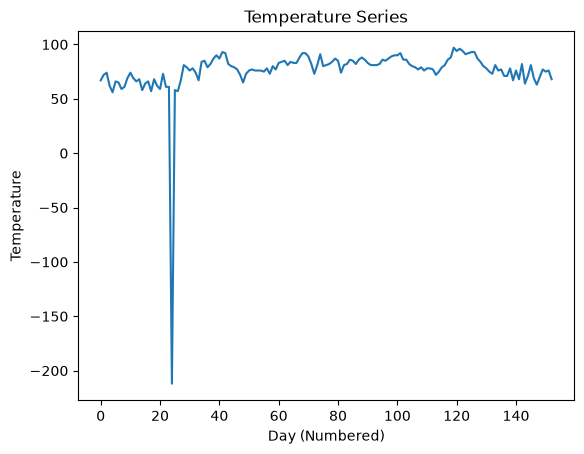

In [6]:
import matplotlib.pyplot as plt

plt.plot(df["Temp"])
plt.title("Temperature Series")
plt.xlabel("Day (Numbered)")
plt.ylabel("Temperature")
plt.show()

Remove the outlier with a mean between it's Neighbours 

In [7]:
before, after = df.loc[i - 1, "Temp"], df.loc[i + 1, "Temp"]
df.loc[i, "Temp"] = (before + after) / 2

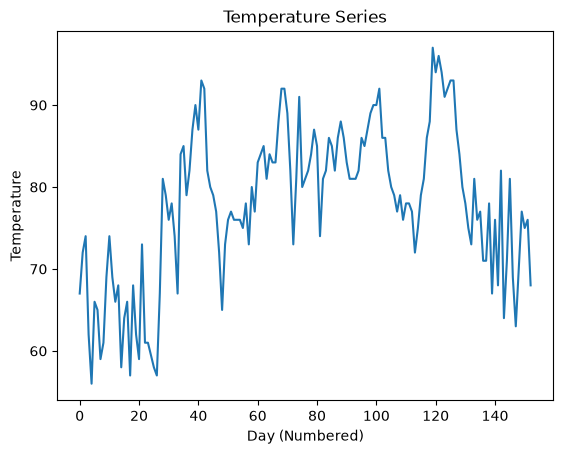

In [8]:
plt.plot(df["Temp"])
plt.title("Temperature Series")
plt.xlabel("Day (Numbered)")
plt.ylabel("Temperature")
plt.show()

### Fahrenheit to Celsius converter, applied with `map()`

In [ ]:
def fahrenheit_to_celsius(f):
    return (f - 32) * 5/9

df["Temp_C"] = df["Temp"].map(fahrenheit_to_celsius)

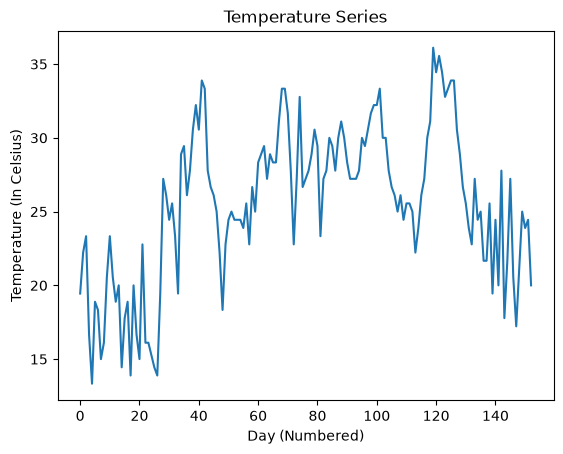

In [12]:
plt.plot(df["Temp_C"])
plt.title("Temperature Series")
plt.xlabel("Day (Numbered)")
plt.ylabel("Temperature (In Celsius)")
plt.show()

### Both temperature graphs in one figure

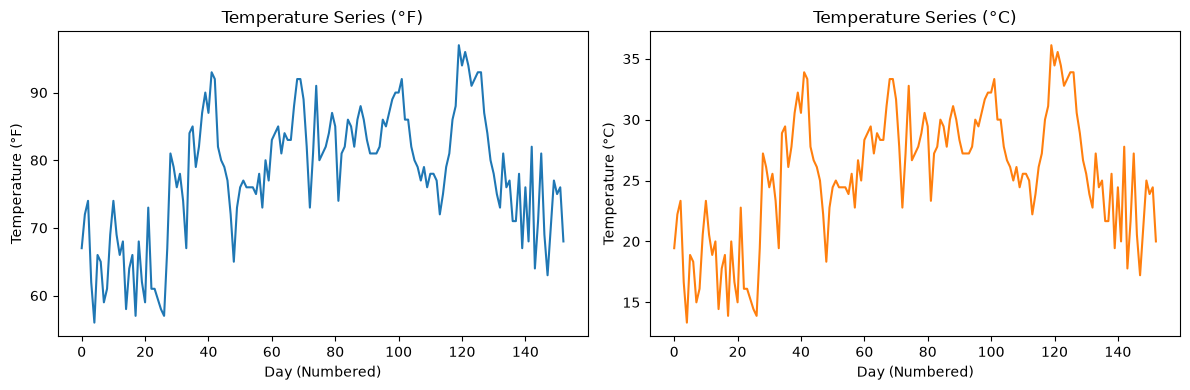

In [18]:
fig = plt.figure(figsize=(12, 4))

ax = fig.add_subplot(1, 2, 1)
ax.plot(df["Temp"])
ax.set_title("Temperature Series (°F)")
ax.set_xlabel("Day (Numbered)")
ax.set_ylabel("Temperature (°F)")

ay = fig.add_subplot(1, 2, 2)
ay.plot(df["Temp_C"], color="tab:orange")
ay.set_title("Temperature Series (°C)")
ay.set_xlabel("Day (Numbered)")
ay.set_ylabel("Temperature (°C)")

fig.tight_layout()

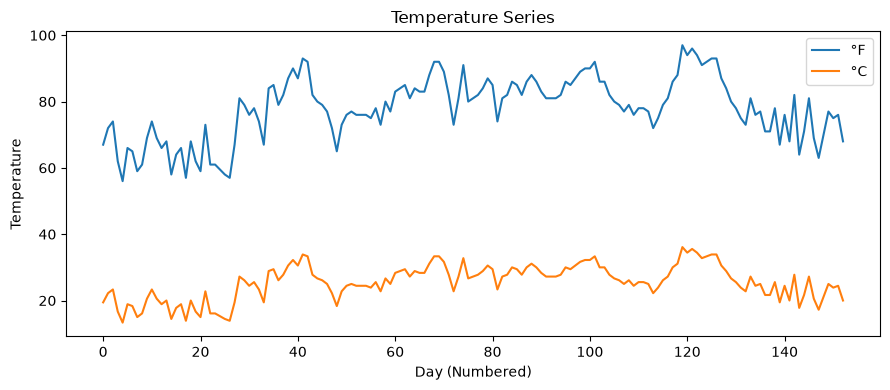

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(df["Temp"], label="°F")
ax.plot(df["Temp_C"], label="°C")

ax.set_title("Temperature Series")
ax.set_xlabel("Day (Numbered)")
ax.set_ylabel("Temperature")
ax.legend()

fig.tight_layout()

In [21]:
df.head()

,rownames,Ozone,Solar.R,Wind,Temp,Month,Day,z_score,Temp_C
0,1.0,41.0,190.0,7.4,67.0,5.0,1.0,-0.362857,19.444444
1,2.0,36.0,118.0,8.0,72.0,5.0,2.0,-0.164013,22.222222
2,3.0,12.0,149.0,12.6,74.0,5.0,3.0,-0.084476,23.333333
3,4.0,18.0,313.0,11.5,62.0,5.0,4.0,-0.561700,16.666667
4,5.0,NaN,NaN,14.3,56.0,5.0,5.0,-0.800312,13.333333


### The `AirQualityReport` class

In [22]:
class AirQualityReport:
    
    def __init__(self, dataframe):
        self.ozone = dataframe["Ozone"].mean()
        self.solar = dataframe["Solar.R"].mean()
        self.wind = dataframe["Wind"].mean()
        self.temp = dataframe["Temp"].mean()
        self.temp_c = dataframe["Temp_C"].mean()
        
    def max_value(self):
        values = {"Ozone": self.ozone, "Solar.R": self.solar, "Wind": self.wind, "Temp": self.temp, "Temp_C": self.temp_c}
        name = max(values, key=values.get)
        return {name: values[name]}
    
    def column_maxima(self, dataframe):
        return dataframe[["Ozone", "Solar.R", "Wind", "Temp"]].max().to_dict()
    

In [25]:
report = AirQualityReport(df)
print(report.max_value())
print(report.column_maxima(df))

{'Solar.R': np.float64(185.93150684931507)}
{'Ozone': 168.0, 'Solar.R': 334.0, 'Wind': 20.7, 'Temp': 97.0}


### Export

From a terminal in this folder, once the notebook is filled in and saved:

```
jupyter nbconvert --to html --no-input sw09_exercises.ipynb
```

Two hyphens before `to` and `no-input`. The slide prints em dashes, which fail. PDF export additionally needs a LaTeX installation.

In [26]:
!jupyter nbconvert --to html --no-input sw09_exercises.ipynb

[NbConvertApp] Converting notebook sw09_exercises.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 5 image(s).
[NbConvertApp] Writing 624398 bytes to sw09_exercises.html


### Part b)

Answer the following questions:

- How many and which channels are above the 99 percentile of `Watch_time`?
- What are the top 10 languages measured by sum of all `Peak_viewers` in that language?

```python
# Hint: numpy provides a percentile function
value = np.percentile(data, 95)

# Hint: masks are created by boolean expressions
mask = df['Watch_time'] > your_value

# Hint: masks can be used to select parts of dataframes
res_df = df.loc[mask, "MyColumn"]

# Hint: dataframes groupby function allows to group by column values
gr = df.groupby('label')

# Hint: aggregation functions as sum() can be called directly on the result of groupby.
gr = df.groupby('label').sum()
```

### Part c)

Based on the result of part b):

- Visualize the obtained sum for `Peak_viewers` for the top 10 languages as a barplot using matplotlib
- Drop English. For the remaining 9 languages, create a heatmap using seaborn
  - Use the columns `Peak_viewers`, `Watch_time`, `Followers`
  - To make them comparable, use min-max-normalization on each column
- Combine both plots in one matplotlib figure using `plt.subplots(1,2)`

```python
# Hint: min max normalization for each column
result_df = (df - df.min()) / (df.max() - df.min())  # column wise min max normalization
```